<a href="https://colab.research.google.com/github/erikh-1126/05-Project-Group/blob/main/05_neural_networks_real_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🧪 LAB: Machine Learning to Predict Concrete Compressive Strength

In this lab, you will apply `PyTorch` to a real-world data problem. You will implement a Neural Network in `PyTorch` using the new functionalities introduced this week and compare its performance with a Support Vector Machine and Linear Regression.

Your goal is to predict the **compressive strength of concrete** (the outcome variable, *Y*) based on a set of input features (*X*), including:
**Cement, Blast Furnace Slag, Fly Ash, Water, Superplasticizer, Coarse Aggregate, Fine Aggregate, and Age.**

This dataset and problem are based on the following paper:

- I-Cheng Yeh, "Modeling of strength of high performance concrete using artificial neural networks," Cement and Concrete Research, Vol. 28, No. 12, pp. 1797-1808 (1998). [Link to the paper](yeh1998.pdf).


---

**Collaboration Note**: This assignment is designed to support collaborative work. We encourage you to divide tasks among group members so that everyone can contribute meaningfully. Many components of the assignment can be approached in parallel or split logically across team members. Good coordination and thoughtful integration of your work will lead to a stronger final result.

---

In total, this lab assignment will be worth **100 points**.

---
**Submission notes**:

* Write down all group members' names, or at least the group name (if you have one and you previously provided it), in the first cell of the notebook.

* Verify that the notebook runs as expected and that all required outputs are included.

NAME(s) = ""

## 0. Overall Instructions

In this lab, you will work with three models: a **Neural Network**, a **Support Vector Machine (SVM)**, and some form of **Linear Regression**. Each should meet the following requirements:

- **Do not tune the models**. For example, for the Neural Network, choose any number of layers and hidden units you prefer; for the SVM, select a kernel of your choice (e.g., linear, RBF, polynomial), etc.

- **Evaluate model performance using k-fold cross-validation**. That is, run each model using a chosen number of folds (*k*), and report the average performance across all folds. You may select the value of *k* that you want.

- **Be careful with data preprocessing**. Apply all preprocessing steps properly to avoid data leakage (e.g. standardizing features before data splitting)

## 1. Pre-implementation Group Discussion (15 points)

In your group, discuss, agree on, and elaborate the following points:

- **Descriptive analysis**. Identify what exploratory or descriptive analyses you can perform to better understand the relationship between each input variable and the outcome. Consider both visual (e.g., scatter plots, histograms) and statistical summaries.

- **Data preprocessing**. Decide what preprocessing steps are necessary given that you will be using neural networks.

- **Model configuration**. Specify which cost function and output layer activation are most appropriate for your problem type (e.g., regression vs. classification). Explain your reasoning based on the nature of the outcome variable.

- **Performance evaluation**. Describe how you will perform k-fold cross-validation to assess your model’s performance. Include how you will divide the data, compute metrics across folds, and report the final averaged results.

Descriptive analysis: We will make a heat map, scatter plot, and a top coefficients model to better visualize our data. We will also include basic statistics like mean, standard deviation, minimum, maximum, and quartiles for each variable.
Data Preprocessing: We will remove any null values, create a train-holdout set, and scale the training and potentially the holdout set.
Model configuration: cost function is MSE and there is no activation function needed, just one node needed
Model configuration: This will be a regression function with only one node. There won't be an activation function for the last output layer, but there is amongst the hidden layers. The cost function will be MSE, RMSE, and R^2
Performance evaluation: We will use 5-fold cross-validation by randomly dividing the data into five approximately equal groups. In each round, we will train the model on four groups and evaluate it on the remaining group, repeating this until every group has been used for evaluation once.

For each fold, we will fit the scaler only on the training data and use it to transform both the training and validation data to avoid data leakage. We will also initialize and train a fresh model for each fold.

We will calculate MSE, RMSE, and \(R^2\) on each validation fold and report the mean and standard deviation across all five folds. Lower MSE and RMSE indicate smaller prediction errors, while higher \(R^2\) indicates better predictive performance. RMSE is especially useful because it expresses the prediction error in MPa, the same unit as concrete compressive strength.

## 2. Descriptive analysis (10 points)

Apply the descriptive analyses that your group agreed upon in the previous section.

**Load the dataset before beginning the descriptive analysis; you will also use it in the following sections.**

Dataset shape: (1030, 9)

Column names:
['Cement (component 1)(kg in a m^3 mixture)', 'Blast Furnace Slag (component 2)(kg in a m^3 mixture)', 'Fly Ash (component 3)(kg in a m^3 mixture)', 'Water  (component 4)(kg in a m^3 mixture)', 'Superplasticizer (component 5)(kg in a m^3 mixture)', 'Coarse Aggregate  (component 6)(kg in a m^3 mixture)', 'Fine Aggregate (component 7)(kg in a m^3 mixture)', 'Age (day)', 'Concrete compressive strength(MPa, megapascals)']

Missing values:
Cement (component 1)(kg in a m^3 mixture)                0
Blast Furnace Slag (component 2)(kg in a m^3 mixture)    0
Fly Ash (component 3)(kg in a m^3 mixture)               0
Water  (component 4)(kg in a m^3 mixture)                0
Superplasticizer (component 5)(kg in a m^3 mixture)      0
Coarse Aggregate  (component 6)(kg in a m^3 mixture)     0
Fine Aggregate (component 7)(kg in a m^3 mixture)        0
Age (day)                                                0
Concrete compressive strength(MPa, megapascals)  

,count,mean,std,min,25%,50%,75%,max
Cement (component 1)(kg in a m^3 mixture),1030.0,281.17,104.51,102.00,192.38,272.90,350.00,540.0
Blast Furnace Slag (component 2)(kg in a m^3 mixture),1030.0,73.90,86.28,0.00,0.00,22.00,142.95,359.4
Fly Ash (component 3)(kg in a m^3 mixture),1030.0,54.19,64.00,0.00,0.00,0.00,118.27,200.1
Water (component 4)(kg in a m^3 mixture),1030.0,181.57,21.36,121.75,164.90,185.00,192.00,247.0
Superplasticizer (component 5)(kg in a m^3 mixture),1030.0,6.20,5.97,0.00,0.00,6.35,10.16,32.2
Coarse Aggregate (component 6)(kg in a m^3 mixture),1030.0,972.92,77.75,801.00,932.00,968.00,1029.40,1145.0
Fine Aggregate (component 7)(kg in a m^3 mixture),1030.0,773.58,80.18,594.00,730.95,779.51,824.00,992.6
Age (day),1030.0,45.66,63.17,1.00,7.00,28.00,56.00,365.0
"Concrete compressive strength(MPa, megapascals)",1030.0,35.82,16.71,2.33,23.71,34.44,46.14,82.6


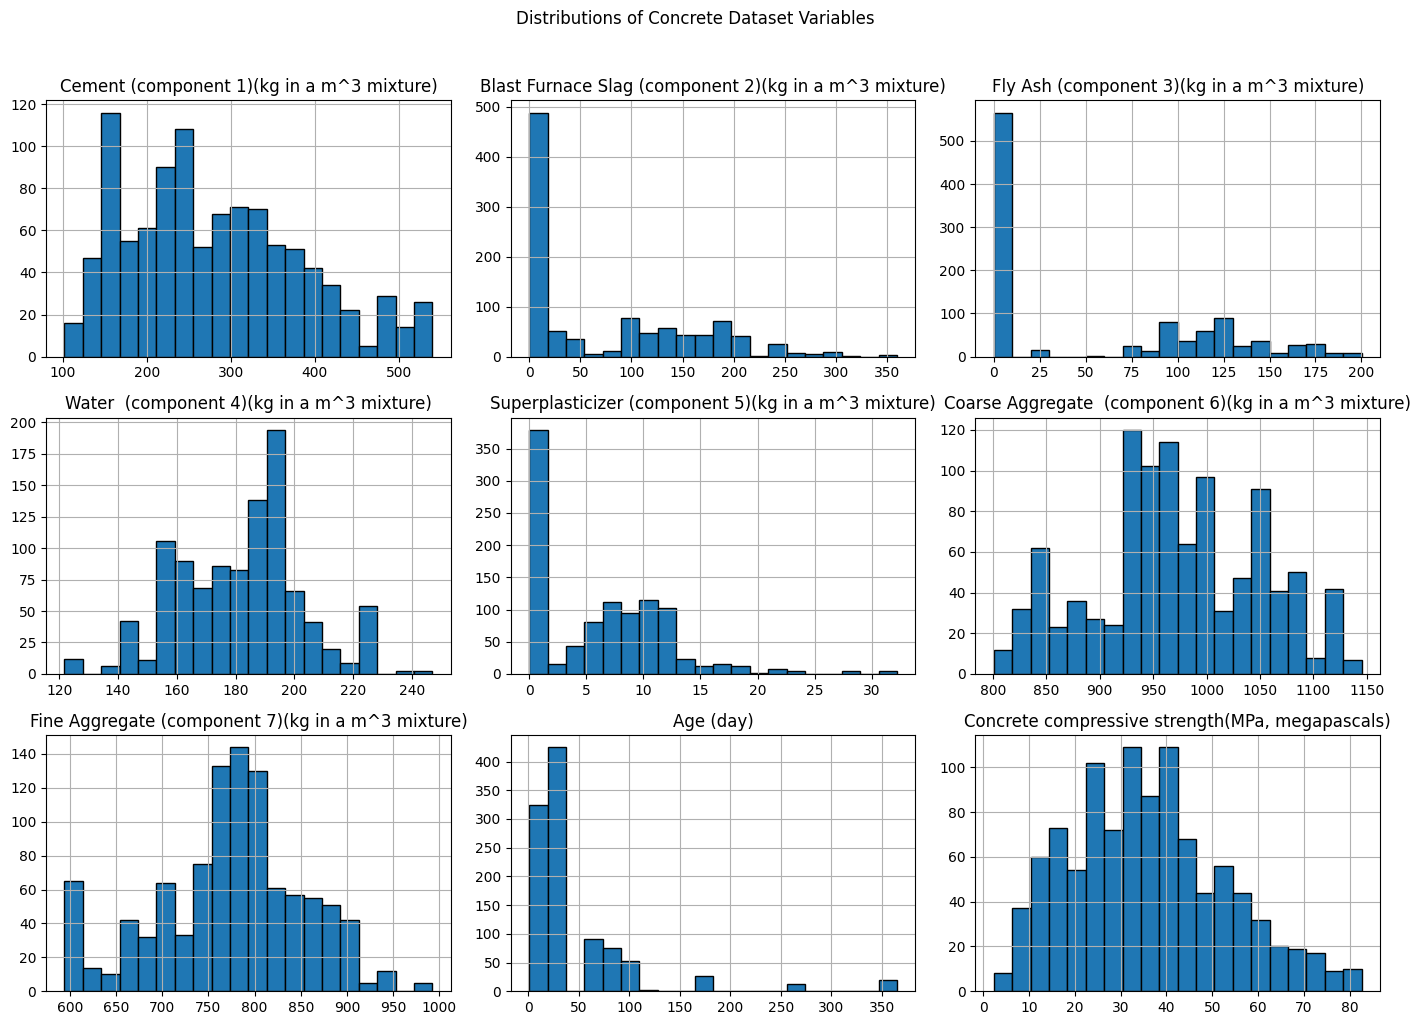

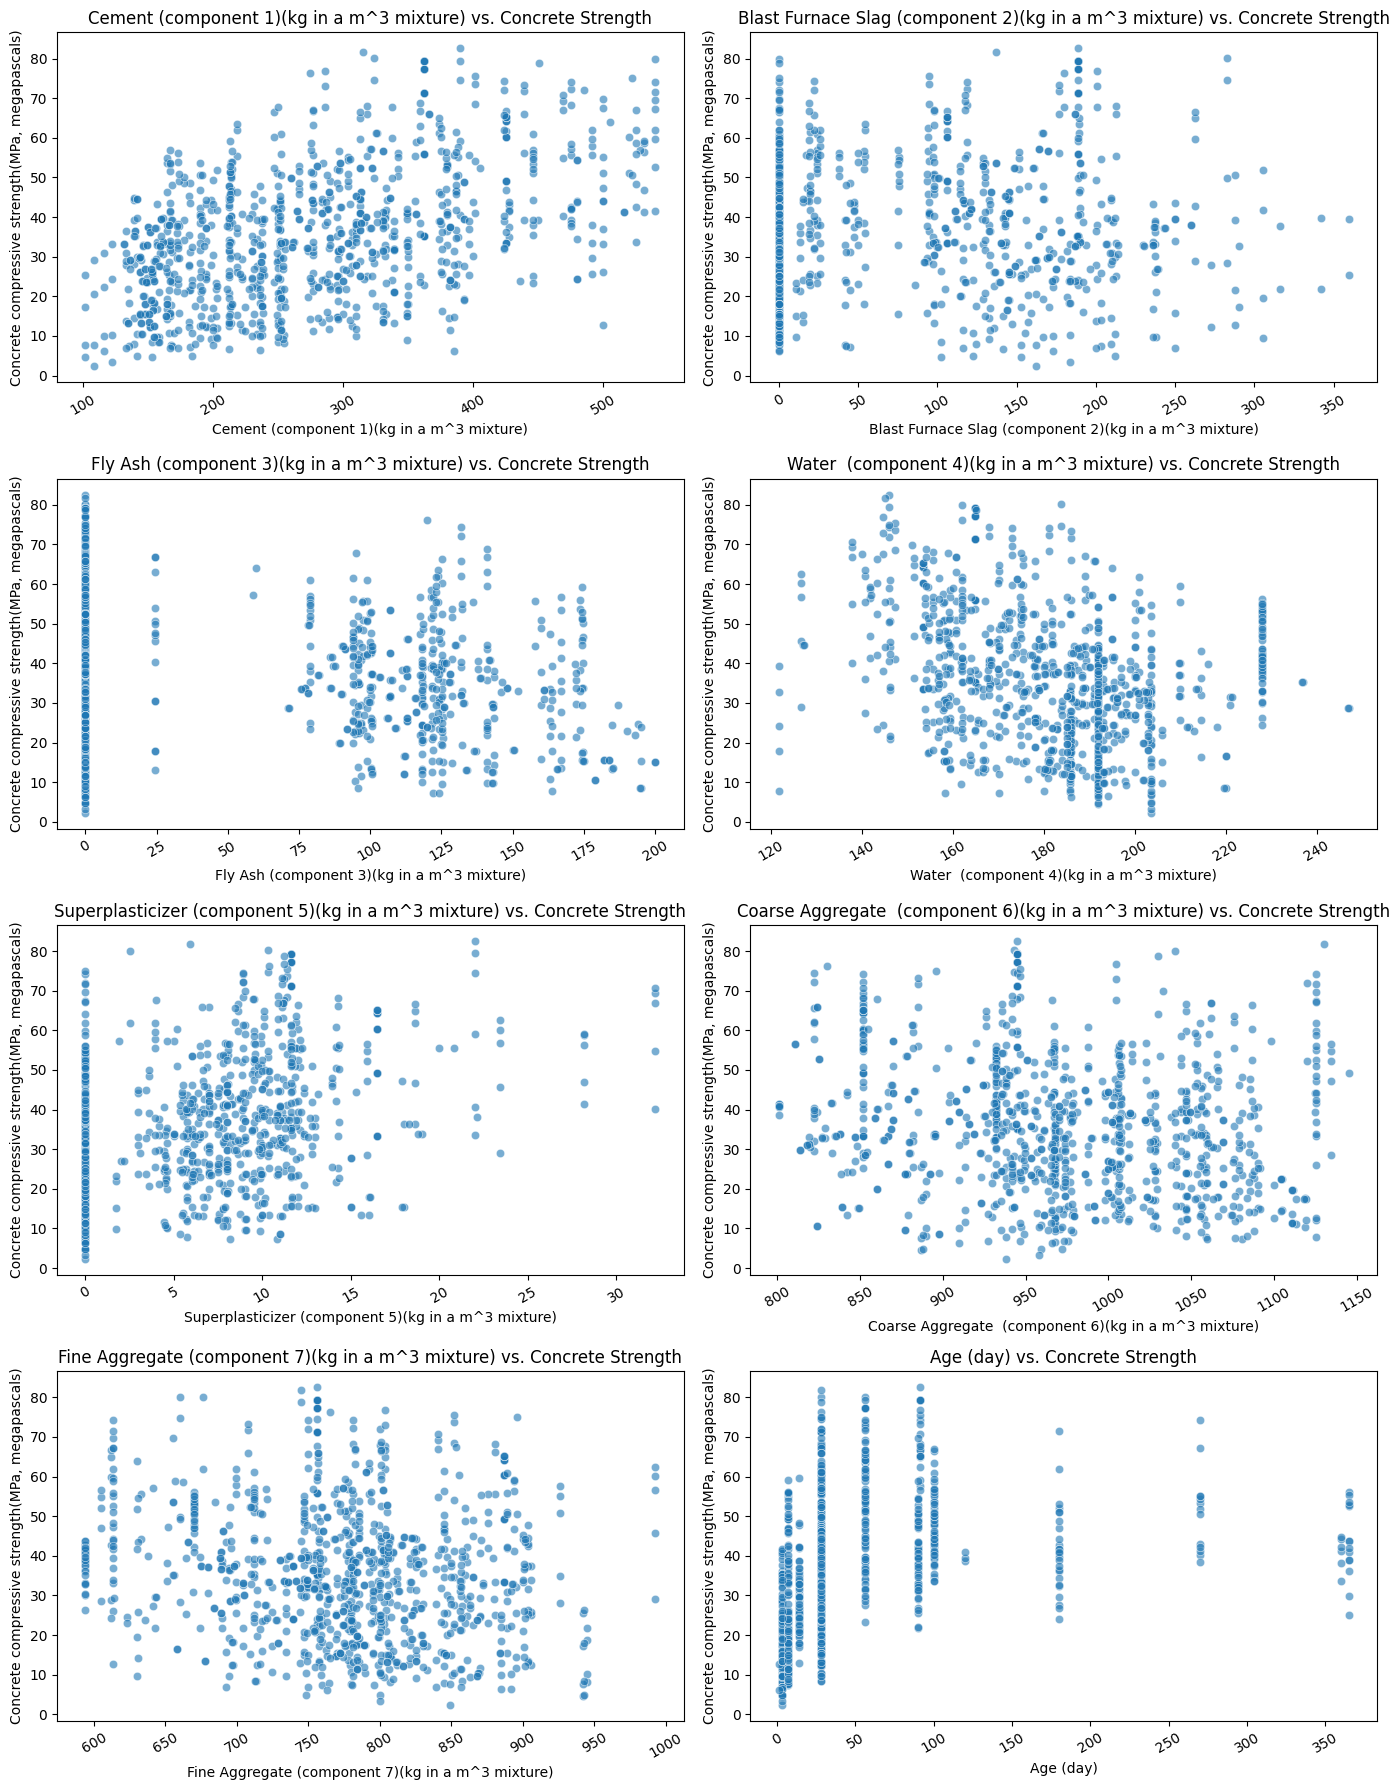

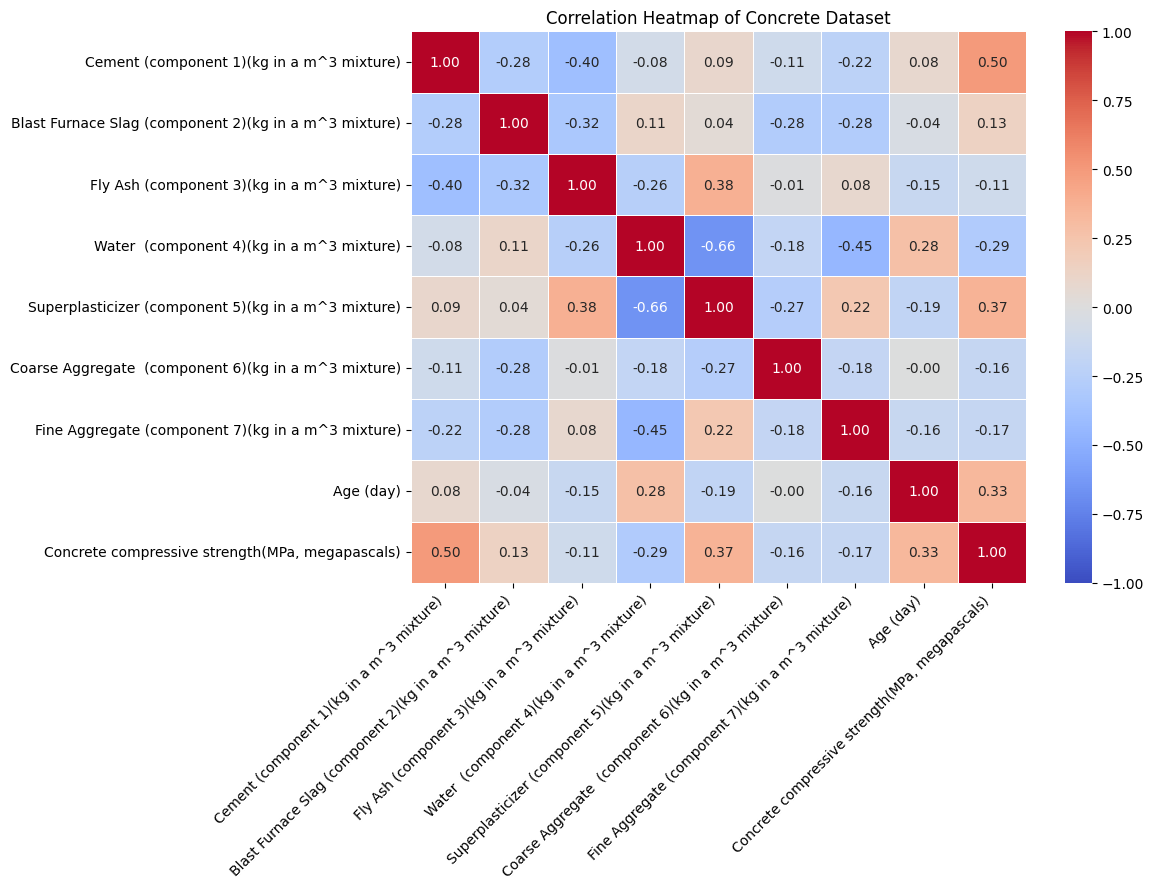


Correlation with Concrete Compressive Strength:


,Correlation
Cement (component 1)(kg in a m^3 mixture),0.498
Superplasticizer (component 5)(kg in a m^3 mixture),0.366
Age (day),0.329
Water (component 4)(kg in a m^3 mixture),-0.290
Fine Aggregate (component 7)(kg in a m^3 mixture),-0.167
Coarse Aggregate (component 6)(kg in a m^3 mixture),-0.165
Blast Furnace Slag (component 2)(kg in a m^3 mixture),0.135
Fly Ash (component 3)(kg in a m^3 mixture),-0.106


In [6]:

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load the dataset
df = pd.read_excel("Concrete_Data.xls")

# Clean column names by removing leading/trailing spaces
df.columns = df.columns.str.strip()

# Identify the target variable and input features
target = next(
    col for col in df.columns
    if "compressive strength" in col.lower()
)

features = [col for col in df.columns if col != target]

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

# Check for missing values and duplicate rows
print("\nMissing values:")
print(df.isnull().sum())

print("\nNumber of duplicate rows:", df.duplicated().sum())

# 1. Descriptive statistics
print("\nDescriptive Statistics:")
display(df.describe().T.round(2))

# 2. Scatter plots: each input variable vs. concrete strength
fig, axes = plt.subplots(4, 2, figsize=(14, 18))
axes = axes.flatten()

for i, feature in enumerate(features):
    sns.scatterplot(
        data=df,
        x=feature,
        y=target,
        alpha=0.6,
        ax=axes[i]
    )
    axes[i].set_title(f"{feature} vs. Concrete Strength")
    axes[i].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

# 3. Correlation heatmap
corr = df.corr(numeric_only=True)

plt.figure(figsize=(12, 9))
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Concrete Dataset")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()



In [7]:

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Separate input features (X) and target (y)
X = df.drop(columns=[target])
y = df[target]

# Split into 80% training and 20% holdout data
X_train, X_holdout, y_train, y_holdout = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

# Standardize the input features
scaler = StandardScaler()

# Fit only on training data to prevent data leakage
X_train_scaled = scaler.fit_transform(X_train)

# Apply the same scaling to holdout data
X_holdout_scaled = scaler.transform(X_holdout)

# Check the split sizes
print("Training set:", X_train_scaled.shape)
print("Holdout set:", X_holdout_scaled.shape)
print("Training targets:", y_train.shape)
print("Holdout targets:", y_holdout.shape)


Training set: (824, 8)
Holdout set: (206, 8)
Training targets: (824,)
Holdout targets: (206,)


## 3. Neural Network (40 points)

Implement a neural network as you did in the previous lab, but this time leverage the new functionalities introduced this week. Specifically:

- Your class implementing the neural network should inherit from nn.Module.

- Use `nn.Linear` for the linear transformations between layers, `nn.ReLU` for the hidden-layer activations, and the appropriate activation function for the output layer (e.g., `nn.Sigmoid` for binary classification).

- Use the appropriate cost function from `torch.nn` for your task (e.g., `nn.MSELoss`, `nn.BCELoss`).

- Use Adam from `torch.optim` as the optimizer.

- Use `DataLoader` to efficiently do batch processing. You may choose the batch size freely.

Once you have implemented this class, create an instance of it, then train and evaluate your model on the lab dataset.

**Remember to follow the general requirements regarding model tuning, evaluation, and data preprocessing described earlier.**

In [ ]:
# USE AS MANY CELLS AS NEEDED

## 4. Replication (10 points)

Replicate your neural network experiment using the corresponding model class from `scikit-learn`: https://scikit-learn.org/stable/api/sklearn.neural_network.html. Be sure to apply the same neural network architecture as well as the same procedures for model evaluation and preprocessing to ensure a fair comparison.

**Remember**: Follow the general requirements regarding model tuning, evaluation, and data preprocessing described earlier.

In [ ]:
# USE AS MANY CELLS AS NEEDED

## 5. Comparison (20 points)

Apply a Support Vector Machine (SVM) and Linear Regression model to the dataset, and compare their performance with that of your Neural Network.

Discuss any similarities or differences you observe in their results and provide possible explanations for these patterns.

Be sure to apply the k-fold cross-validation procedure to ensure a fair comparison across all models.

**Remember**: Follow the general requirements regarding model tuning, evaluation, and data preprocessing described earlier.

In [ ]:
# USE AS MANY CELLS AS NEEDED

## 6. Collaboration Reflection (5 points)

As a group, identify **one specific challenge or inefficiency** you encountered while working on this lab. In 3–5 sentences:

1. Briefly describe what happened and how it affected your work.
2. Identify one concrete action your group will take to avoid or better manage this issue in the next lab.

If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.

YOUR TEXT HERE